# London Transport Visualizations
## Part 2: Elizabeth Line, DLR, and Trams

This notebook visualizes the additional transport lines: Elizabeth line, Docklands Light Railway (DLR), and London Trams.

In [10]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

# Colors for the additional lines (official TfL colors)
ADDITIONAL_LINE_COLORS = {
    'DLR': '#00A4A7',  # DLR - Teal
    'ELZ': '#6950A1',  # Elizabeth - Purple
    'TRM': '#84B817',  # Trams - Lime Green
}

ADDITIONAL_LINE_NAMES = {
    'DLR': 'DLR',
    'ELZ': 'Elizabeth',
    'TRM': 'Trams',
}

# All tube line colors for context
TUBE_LINE_COLORS = {
    'BAK': '#B36305', 'CEN': '#E32017', 'CIR': '#FFD300', 'DIS': '#00782A',
    'HAM': '#F3A9BB', 'JUB': '#A0A5A9', 'MET': '#9B0056', 'NTN': '#000000',
    'PIC': '#003688', 'VIC': '#0098D4', 'WAC': '#95CDBA',
}

## Load Station Data

In [11]:
# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} stations")

# Convert coordinates
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Try to use pyproj for accurate conversion
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
    coords = transformer.transform(stops['Easting'].values, stops['Northing'].values)
    stops['Longitude'] = coords[0]
    stops['Latitude'] = coords[1]
    print("Used pyproj for accurate coordinate conversion")
except ImportError:
    print("pyproj not available, using approximate conversion")
    stops['Latitude'] = 49.0 + (stops['Northing'] / 111000)
    stops['Longitude'] = -7.5 + (stops['Easting'] / (111000 * np.cos(np.radians(stops['Latitude']))))

# Create coordinate lookup
stop_coords = stops.set_index('AtcoCode')[['Easting', 'Northing', 'Latitude', 'Longitude', 'Descriptor_CommonName']].to_dict('index')
stops.head()

Loaded 691 stations
Used pyproj for accurate coordinate conversion


,AtcoCode,Descriptor_CommonName,Place_NptgLocalityRef,Place_Location_Easting,Place_Location_Northing,Latitude,Longitude,Zone,Easting,Northing
0,9400ZZLUWIM1,Wimbledon,E0034695,524793,170673,51.421341,-0.206625,NaN,524793,170673
1,9400ZZLUWIP1,Wimbledon Park,E0034696,525266,172129,51.434322,-0.199312,NaN,525266,172129
2,9400ZZLUSFS1,Southfields Station,E0034902,524715,173348,51.445399,-0.206805,NaN,524715,173348
3,9400ZZLUEPY1,East Putney,N0077656,524371,174824,51.458739,-0.211234,NaN,524371,174824
4,9400ZZLUPYB1,Putney Bridge,N0077709,524512,175890,51.468288,-0.208830,NaN,524512,175890


## Load Route Links for Additional Lines

In [12]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique station-to-station edges from route links."""
    return route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()

# Load additional lines
additional_edges = {}
for line_code in ADDITIONAL_LINE_COLORS.keys():
    links = load_route_links(line_code)
    if links is not None:
        edges = get_unique_edges(links)
        additional_edges[line_code] = edges
        print(f"{ADDITIONAL_LINE_NAMES[line_code]}: {len(edges)} unique edges")
    else:
        print(f"{ADDITIONAL_LINE_NAMES[line_code]}: No data found")

# Load tube lines for context
tube_edges = {}
for line_code in TUBE_LINE_COLORS.keys():
    links = load_route_links(line_code)
    if links is not None:
        tube_edges[line_code] = get_unique_edges(links)

DLR: 97 unique edges
Elizabeth: 84 unique edges
Trams: 71 unique edges


In [13]:
def plot_line(ax, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a single line on the axes."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['Easting'], stop_coords[to_stop]['Easting']]
            y = [stop_coords[from_stop]['Northing'], stop_coords[to_stop]['Northing']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

## Individual Line Maps

Visualize each additional line individually.

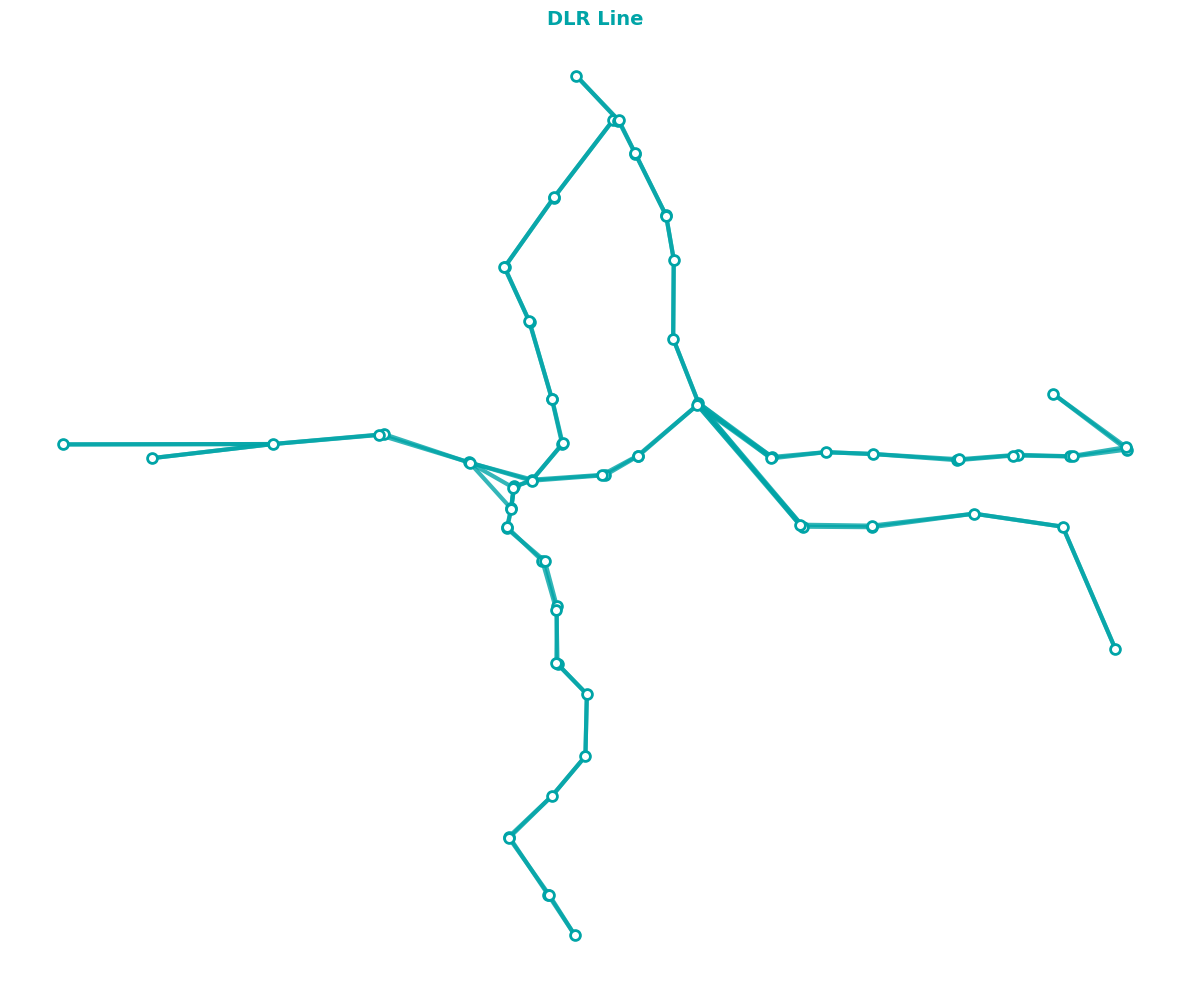

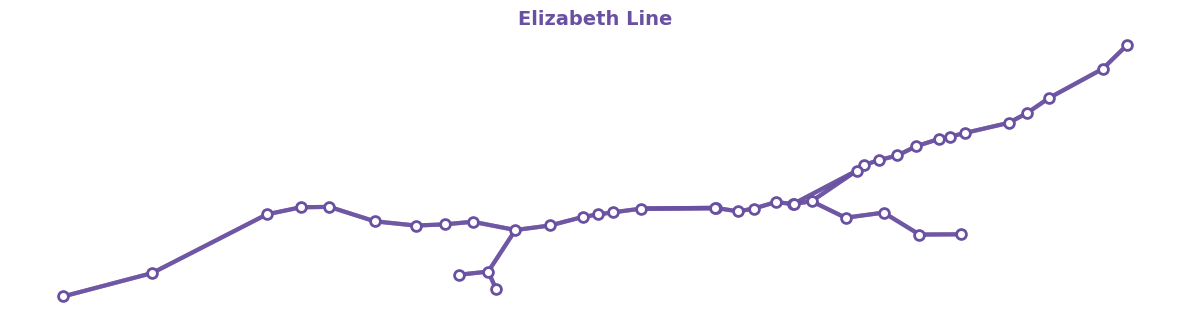

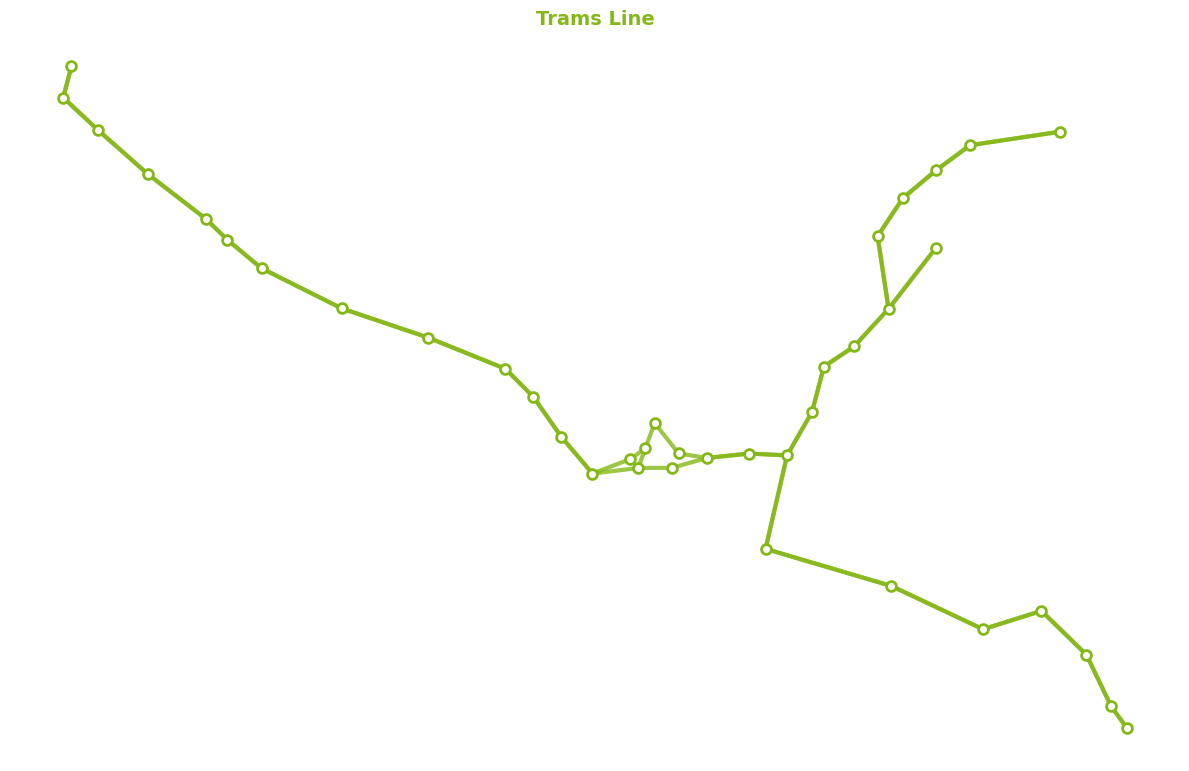

In [14]:
def plot_single_line(line_code, edges, stop_coords, color, title):
    """Create a map for a single line."""
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Get stations on this line
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Draw edges
    plot_line(ax, edges, stop_coords, color, linewidth=3)
    
    # Draw stations
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=50, edgecolors=color, linewidth=2, zorder=10)
    
    ax.set_title(title, fontsize=14, color=color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    return fig, ax

# Plot each additional line individually
for line_code, edges in additional_edges.items():
    fig, ax = plot_single_line(line_code, edges, stop_coords, 
                               ADDITIONAL_LINE_COLORS[line_code], 
                               f"{ADDITIONAL_LINE_NAMES[line_code]} Line")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'line_{line_code.lower()}.png', dpi=150, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    plt.show()

## All Additional Lines Together

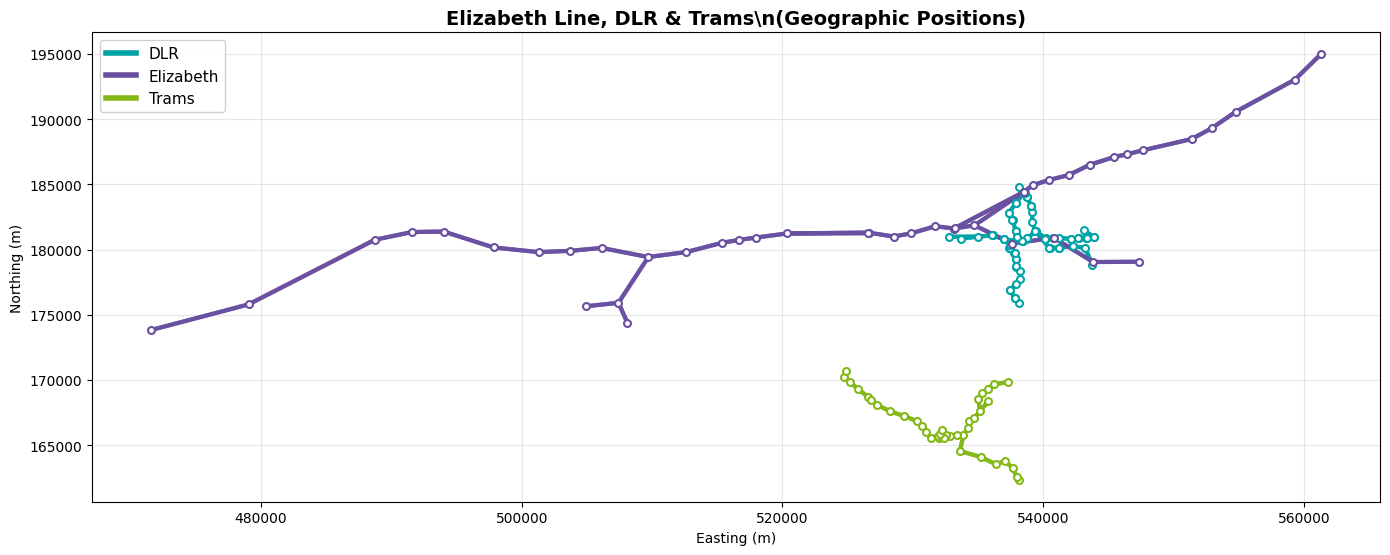

In [15]:
fig, ax = plt.subplots(figsize=(14, 16))

# Draw all additional lines with their colors
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=3, alpha=0.9)

# Collect all stations from additional lines
all_stations = set()
for edges in additional_edges.values():
    all_stations.update(edges['From_StopPointRef'].tolist())
    all_stations.update(edges['To_StopPointRef'].tolist())

# Draw stations with line-specific colors
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=25, edgecolors=color, linewidth=1.5, zorder=10)

# Add labels for terminus/key stations
labeled_stations = set()
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    line_stations = list(set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist()))
    
    # Find terminus stations (appear only once in edges)
    station_counts = {}
    for _, edge in edges.iterrows():
        station_counts[edge['From_StopPointRef']] = station_counts.get(edge['From_StopPointRef'], 0) + 1
        station_counts[edge['To_StopPointRef']] = station_counts.get(edge['To_StopPointRef'], 0) + 1
    
    terminus_stations = [s for s, count in station_counts.items() if count == 1]
    
    for station in terminus_stations:
        if station in stop_coords and station not in labeled_stations:
            name = stop_coords[station].get('Descriptor_CommonName', '')
            if name:
                ax.annotate(name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(5, 5), textcoords='offset points',
                           fontsize=7, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor=color))
                labeled_stations.add(station)

ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title('Elizabeth Line, DLR & Trams\\n(Geographic Positions)', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Add legend with colored lines
legend_elements = [Line2D([0], [0], color=ADDITIONAL_LINE_COLORS[code], linewidth=4, 
                          label=ADDITIONAL_LINE_NAMES[code])
                   for code in ['DLR', 'ELZ', 'TRM'] if code in additional_edges]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'additional_lines_network.png', dpi=150, bbox_inches='tight')
plt.show()

## Combined View: Tube Network + Additional Lines

Show the additional lines in context with the Underground network.

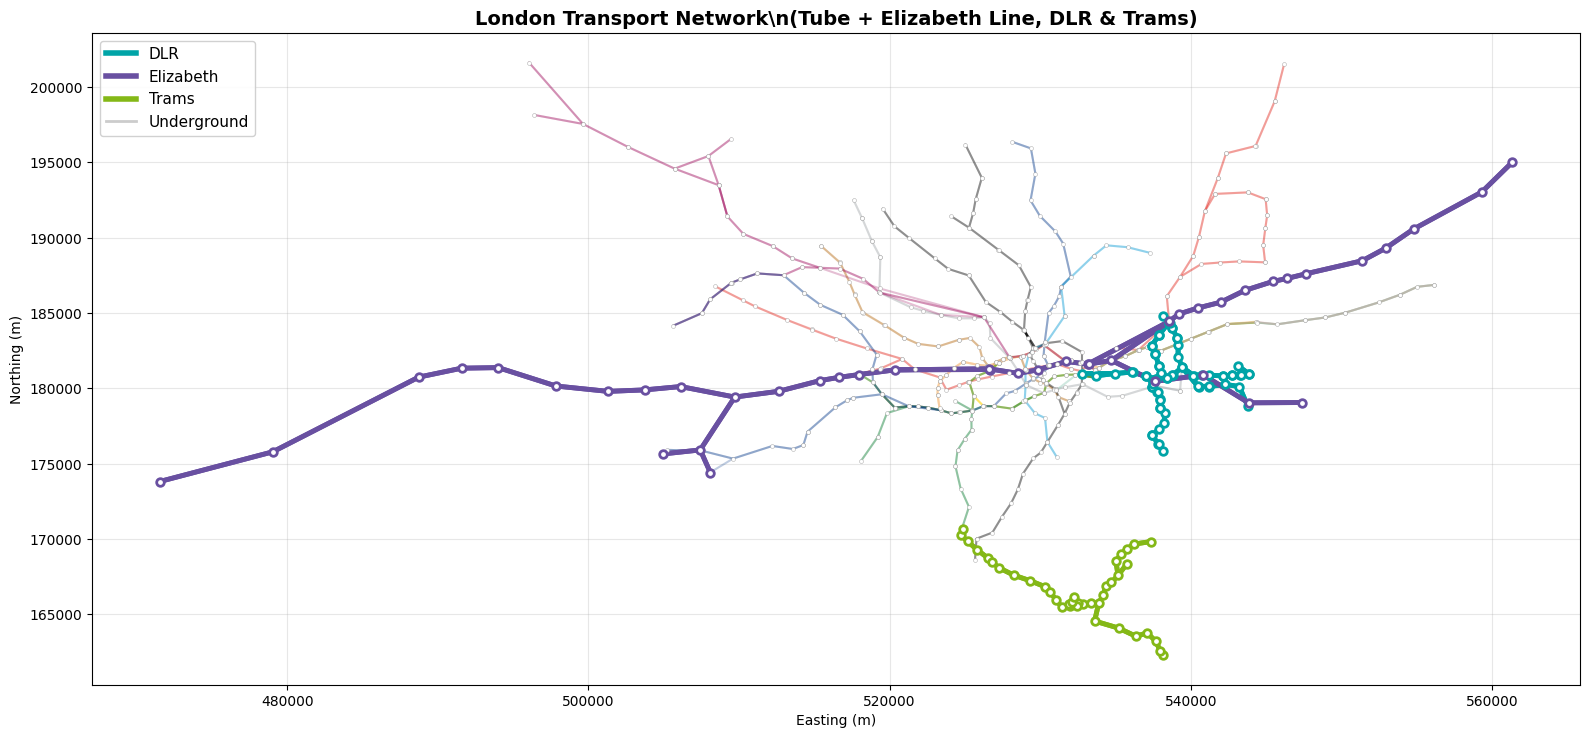

In [16]:
fig, ax = plt.subplots(figsize=(16, 18))

# Draw tube lines (dimmed for context)
for line_code, edges in tube_edges.items():
    plot_line(ax, edges, stop_coords, TUBE_LINE_COLORS[line_code], linewidth=1.5, alpha=0.25)

# Draw additional lines (highlighted) with their colors
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=3.5, alpha=1.0)

# Collect all stations
all_stations = set()
for edges in tube_edges.values():
    all_stations.update(edges['From_StopPointRef'].tolist())
    all_stations.update(edges['To_StopPointRef'].tolist())

# Draw tube stations (small, grey)
for station in all_stations:
    if station in stop_coords:
        ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                  c='white', s=8, edgecolors='#999999', linewidth=0.3, zorder=5)

# Draw additional line stations with their colors (larger, on top)
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=30, edgecolors=color, linewidth=2, zorder=10)

# Add labels for key stations on additional lines
labeled_stations = set()
for line_code, edges in additional_edges.items():
    color = ADDITIONAL_LINE_COLORS[line_code]
    
    # Find terminus stations
    station_counts = {}
    for _, edge in edges.iterrows():
        station_counts[edge['From_StopPointRef']] = station_counts.get(edge['From_StopPointRef'], 0) + 1
        station_counts[edge['To_StopPointRef']] = station_counts.get(edge['To_StopPointRef'], 0) + 1
    
    terminus_stations = [s for s, count in station_counts.items() if count == 1]
    
    for station in terminus_stations:
        if station in stop_coords and station not in labeled_stations:
            name = stop_coords[station].get('Descriptor_CommonName', '')
            if name:
                ax.annotate(name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(5, 5), textcoords='offset points',
                           fontsize=6, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor=color))
                labeled_stations.add(station)

ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title('London Transport Network\\n(Tube + Elizabeth Line, DLR & Trams)', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Add legend for additional lines with colors
legend_elements = [Line2D([0], [0], color=ADDITIONAL_LINE_COLORS[code], linewidth=4, 
                          label=ADDITIONAL_LINE_NAMES[code])
                   for code in ['DLR', 'ELZ', 'TRM'] if code in additional_edges]
legend_elements.append(Line2D([0], [0], color='gray', linewidth=2, alpha=0.4, label='Underground'))
ax.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'combined_network_additional_highlighted.png', dpi=150, bbox_inches='tight')
plt.show()

## Side-by-Side Comparison

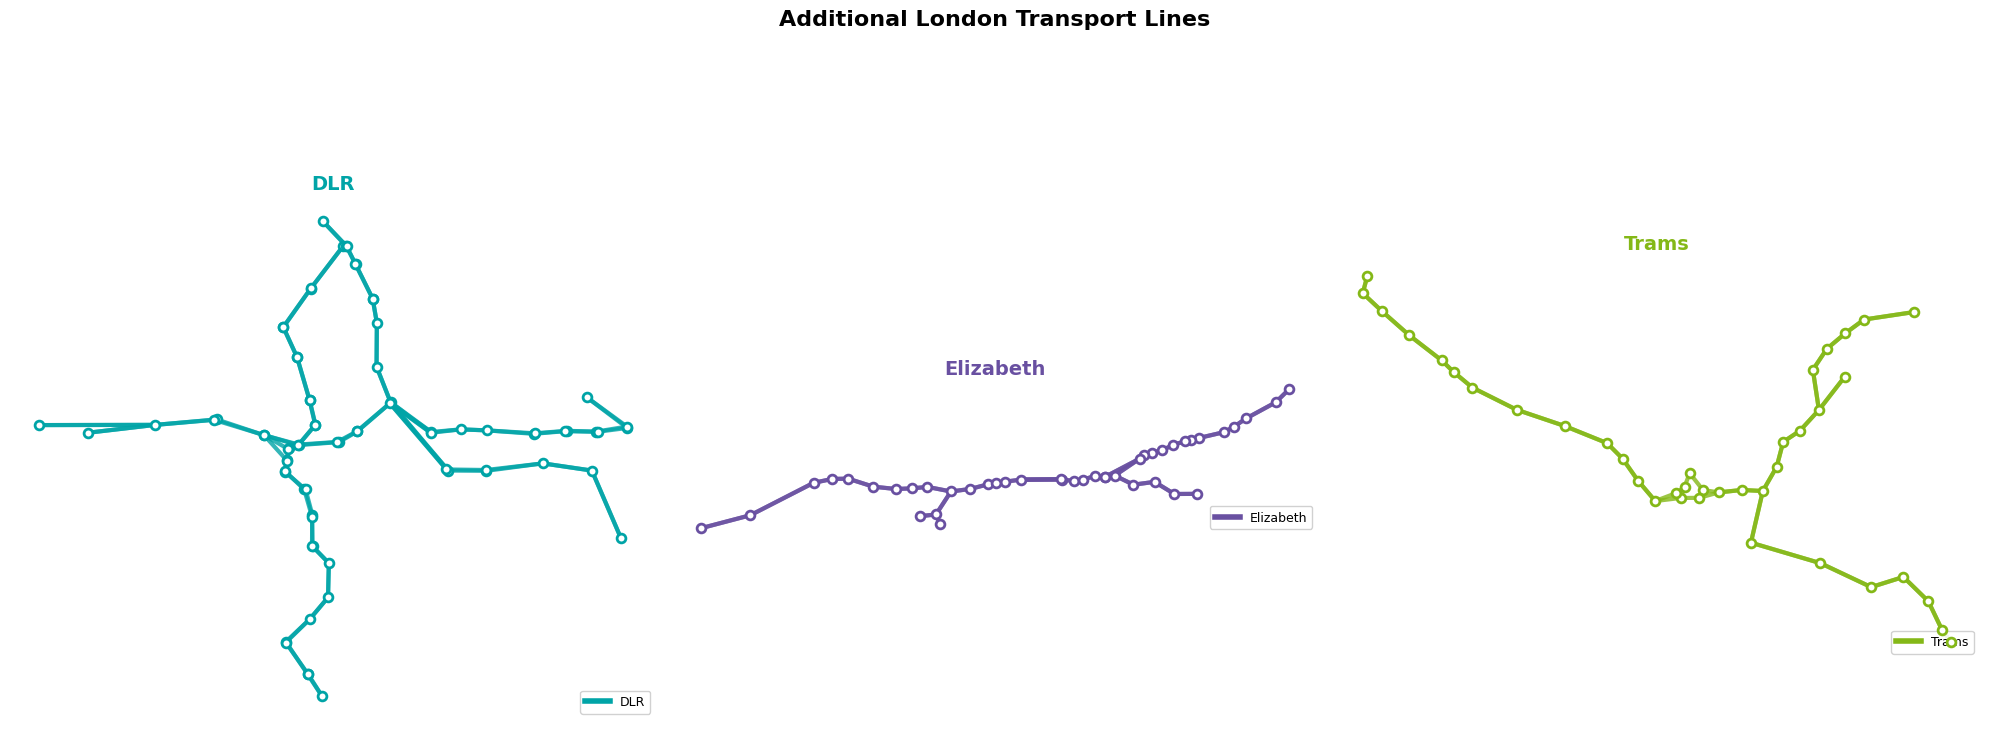

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9))

for idx, (line_code, ax) in enumerate(zip(['DLR', 'ELZ', 'TRM'], axes)):
    if line_code not in additional_edges:
        ax.text(0.5, 0.5, f'No data for {ADDITIONAL_LINE_NAMES[line_code]}', 
                ha='center', va='center', transform=ax.transAxes, fontsize=12)
        ax.axis('off')
        continue
    
    edges = additional_edges[line_code]
    color = ADDITIONAL_LINE_COLORS[line_code]
    name = ADDITIONAL_LINE_NAMES[line_code]
    
    # Get stations on this line
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Draw edges with line color
    plot_line(ax, edges, stop_coords, color, linewidth=3)
    
    # Draw stations with line color
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=40, edgecolors=color, linewidth=2, zorder=10)
    
    # Find and label terminus stations
    station_counts = {}
    for _, edge in edges.iterrows():
        station_counts[edge['From_StopPointRef']] = station_counts.get(edge['From_StopPointRef'], 0) + 1
        station_counts[edge['To_StopPointRef']] = station_counts.get(edge['To_StopPointRef'], 0) + 1
    
    terminus_stations = [s for s, count in station_counts.items() if count == 1]
    
    for station in terminus_stations:
        if station in stop_coords:
            station_name = stop_coords[station].get('Descriptor_CommonName', '')
            if station_name:
                ax.annotate(station_name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(4, 4), textcoords='offset points',
                           fontsize=7, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor=color))
    
    # Title with line color
    ax.set_title(name, fontsize=14, color=color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Add a colored legend box for this line
    legend_element = [Line2D([0], [0], color=color, linewidth=4, label=name)]
    ax.legend(handles=legend_element, loc='lower right', fontsize=9, framealpha=0.9)

plt.suptitle('Additional London Transport Lines', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'additional_lines_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Statistics Summary

In [18]:
print("=" * 50)
print("Additional Lines Statistics")
print("=" * 50)

for line_code, edges in additional_edges.items():
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Count stations with valid coordinates
    valid_stations = [s for s in line_stations if s in stop_coords]
    
    print(f"\n{ADDITIONAL_LINE_NAMES[line_code]}:")
    print(f"  Stations: {len(valid_stations)}")
    print(f"  Edges (connections): {len(edges)}")
    
    # Calculate approximate line length
    total_length = 0
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        if from_stop in stop_coords and to_stop in stop_coords:
            dx = stop_coords[to_stop]['Easting'] - stop_coords[from_stop]['Easting']
            dy = stop_coords[to_stop]['Northing'] - stop_coords[from_stop]['Northing']
            total_length += np.sqrt(dx**2 + dy**2)
    
    print(f"  Approx. total length: {total_length/1000:.1f} km")

print("\n" + "=" * 50)

Additional Lines Statistics

DLR:
  Stations: 75
  Edges (connections): 97
  Approx. total length: 73.6 km

Elizabeth:
  Stations: 43
  Edges (connections): 84
  Approx. total length: 259.3 km

Trams:
  Stations: 39
  Edges (connections): 71
  Approx. total length: 50.9 km

